# Trabajo Práctico Final - Grupo 17

Dataset: https://www.kaggle.com/datasets/ealaxi/banksim1?resource=download

_Dataset creado por_:

Lopez-Rojas, Edgar Alonso ; Axelsson, Stefan
Banksim: A bank payments simulator for fraud detection research Inproceedings
26th European Modeling and Simulation Symposium, EMSS 2014, Bordeaux, France, pp. 144–152, Dime University of Genoa, 2014, ISBN: 9788897999324.
https://www.researchgate.net/publication/265736405_BankSim_A_Bank_Payment_Simulation_for_Fraud_Detection_Research

**Bibliografía de referencia**: https://fraud-detection-handbook.github.io/fraud-detection-handbook/Foreword.html

# 1. Importación de librerías


In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

2026-10-12 18:10:12.622154: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 2. Carga del Dataset

In [3]:
df = pd.read_csv('Dataset/bs140513_032310.csv')

# 3. Exploración inicial de los datos (EDA)

## 3.1 Información de las columnas


| Variable      | Qué significa                    | Tipo conceptual    |
| ------------- | -------------------------------- | ------------------ |
| `step`        | Día de la simulación             | Temporal           |
| `customer`    | Identificador del cliente        | Categórica / ID    |
| `age`         | Rango de edad del cliente        | Categórica ordinal |
| `gender`      | Género/tipo del cliente          | Categórica         |
| `zipcodeOri`  | Código postal de origen/cliente  | Categórica         |
| `merchant`    | Identificador del comercio       | Categórica / ID    |
| `zipMerchant` | Código postal del comercio       | Categórica         |
| `category`    | Categoría del comercio/compra    | Categórica         |
| `amount`      | Importe de la transacción        | Numérica           |
| `fraud`       | Si la transacción es fraudulenta | Target binario     |


## 3.2 Dimensiones del Dataset

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  str    
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  str    
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 45.4 MB


## 3.3 Información general del Dataset

### Transformación de las variables

In [5]:
text_cols = df.select_dtypes(include=['object', 'string']).columns
df[text_cols] = df[text_cols].apply(lambda col: col.str.strip("'"))

#### Eliminación de variables que no estan bien hechas según los creadores 

Estas variables están repetidas o no tienen ningún tipo de relación con la variable objetivo según los autores que crearon el dataset.

In [6]:
df = df.drop(columns=['age', 'gender', 'zipcodeOri', 'zipMerchant'])

## 3.4 Análisis de valores faltantes

In [7]:
df.isnull().sum()

step        0
customer    0
merchant    0
category    0
amount      0
fraud       0
dtype: int64

## 3.5 Análisis estadístico de las variables

### Category

In [8]:
corr = pd.get_dummies(df['category'], dtype=float).corrwith(df['fraud'].astype(float))
corr

es_barsandrestaurants    0.006397
es_contents             -0.004274
es_fashion               0.005618
es_food                 -0.023793
es_health                0.142029
es_home                  0.074078
es_hotelservices         0.149816
es_hyper                 0.031466
es_leisure               0.248495
es_otherservices         0.085249
es_sportsandtoys         0.363631
es_tech                  0.031556
es_transportation       -0.262973
es_travel                0.250284
es_wellnessandbeauty     0.052348
dtype: float64

### Amount

In [9]:
corr = df['amount'].corr(df['fraud'])
corr

np.float64(0.48996664675723606)

# 4. Preparación de los datos (Data Preprocessing)

## 4.1 Feature Engieniering

### Customer

Se va a transformar la variable customer en: Cantidad de transacciones por el cliente i en n dias (1, 7, 30) y el promedio gastado en los ultimos n días (1, 7, 30). Como en la sección 3.3

#### Cantidad transacciónes por cliente

In [10]:
# Hacemos que tenga un orden cronológico
df = df.sort_values(by=["customer", "step"]).reset_index(drop=True)

# Creamos una columna temporal basada en 'step' (1 step = 1 día)
df["step_time"] = pd.to_timedelta(df["step"], unit="D")

# Calculamos el conteo móvil para cada ventana 1 día, 7 días, 30 días)
for days in [1, 7, 30]:
    df[f"tx_count_last_{days}d"] = (
        df.groupby("customer", group_keys=False)
        .rolling(f"{days}D", on="step_time")["step"]
        .count()
        .astype(int)
        .values
    )
    df[f"avg_amount_last_{days}d"] = (
        df.groupby("customer", group_keys=False)
        .rolling(f"{days}D", on="step_time")["amount"]
        .mean()
        .values
    )

# Eliminamos columna temporal 
df.drop(columns=["step_time"], inplace=True)

### Merchant

Se crean nuevas variables con: La cantidad de transacciones que realiza cada merchan y el riesgo de cada merchan. Esto se hace en base a 1, 7 y 30 días. La creación de estas variables debe tener un periodo de delay (7 días), que es el tiempo que se demoraría una operación normal en ser detectada como fraudulenta.

Para calcular el riesgo se utiliza: $Risk = Q Fraud sWindow/Q transactions$ -> Extraido de la bibliografía

In [11]:
df = df.sort_values(by=['merchant', 'step']).reset_index(drop=True)
df['step_time'] = pd.to_timedelta(df['step'], unit='D')

delay = 7 + 1 # El 1 para que la ventana excluya el día actual

# Ventana base del delay (los 7 días inmediatos a ignorar)
tx_delay = (
    df.groupby('merchant', group_keys=False)
    .rolling(f'{delay}D', on='step_time')['step']
    .count()
    .values
)

fraud_delay = (
    df.groupby('merchant', group_keys=False)
    .rolling(f'{delay}D', on='step_time')['fraud']
    .sum()
    .values
)

for days in [1, 7, 30]:
    total_window = delay + days  # 8D, 14D, 37D
    
    tx_total = (
        df.groupby('merchant', group_keys=False)
        .rolling(f'{total_window}D', on='step_time')['step']
        .count()
        .values
    )

    frauds = (
        df.groupby('merchant', group_keys=False)
        .rolling(f'{total_window}D', on='step_time')['fraud']
        .sum()
        .values
    )
    
    # Restar la ventana del delay a la ventana acumulada
    df[f'merchant_tx_delayed_{days}d'] = (tx_total - tx_delay).astype(int)
    risk = (frauds - fraud_delay) / (tx_total - tx_delay)
    df[f'merchant_risk_{days}d'] = np.nan_to_num(risk, nan=0.0)

df.drop(columns=['step_time'], inplace=True)

/tmp/ipykernel_16894/648138435.py:40: RuntimeWarning: invalid value encountered in divide
  risk = (frauds - fraud_delay) / (tx_total - tx_delay)
/tmp/ipykernel_16894/648138435.py:40: RuntimeWarning: invalid value encountered in divide
  risk = (frauds - fraud_delay) / (tx_total - tx_delay)
/tmp/ipykernel_16894/648138435.py:40: RuntimeWarning: invalid value encountered in divide
  risk = (frauds - fraud_delay) / (tx_total - tx_delay)


### Category

Se crea a través de la variable una nueva variable de riesgo para cáda categoria en base a 1, 7 y 30 días siguiendo el procedimiento aplicado en merchant

In [12]:
df = df.sort_values(by=['category','step']).reset_index(drop=True)
df['step_time'] = pd.to_timedelta(df['step'],unit='D')

delay = 7 + 1

category_tx_delay = (
    df.groupby('category', group_keys=False)
    .rolling(f'{delay}D', on='step_time')['fraud']
    .count()
    .values
)

category_fraud_delay = (
    df.groupby('category', group_keys=False)
    .rolling(f'{delay}D', on='step_time')['fraud']
    .sum()
    .values
)

for days in [1, 7, 30]:
    total_window = days + delay

    category_tx_total = (
        df.groupby('category', group_keys=False)
        .rolling(f'{total_window}D', on='step_time')['fraud']
        .count()
        .values
    )

    category_fraud_total = (
        df.groupby('category', group_keys=False)
        .rolling(f'{total_window}D', on='step_time')['fraud']
        .sum()
        .values
    )

    # Ventana histórica desplazada 7 días hacia atrás
    tx_window = category_tx_total - category_tx_delay
    fraud_window = category_fraud_total - category_fraud_delay

    # Número histórico de transacciones
    df[f"category_tx_delayed_{days}d"] = tx_window.astype(int)

    # Riesgo histórico
    df[f"category_risk_{days}d"] = np.divide(
        fraud_window,
        tx_window,
        out=np.zeros_like(fraud_window, dtype=float),
        where=tx_window != 0
    )

df.drop(columns=["step_time"], inplace=True)

### Cantidad Anomala

Es una propuesta que complejiza el trabajo pero podria ofrecer buenos resultados, por lo que se deja como proyecto futuro. 

In [13]:
# df = df.sort_values(["customer", "step"]).reset_index(drop=True)
# df["step_time"] = pd.to_timedelta(df["step"], unit="D")

# for days in [7, 30]:

#     historical_avg = (
#         df.groupby("customer", group_keys=False)
#         .rolling(
#             f"{days}D",
#             on="step_time",
#             closed="left"  # excluye el día/transacción actual
#         )["amount"]
#         .mean()
#         .values
#     )

#     df[f"avg_amount_previous_{days}d"] = historical_avg

#     df[f"amount_vs_average_{days}d"] = np.divide(
#         df["amount"].to_numpy(dtype=float),
#         historical_avg,
#         out=np.full(len(df), np.nan),
#         where=~np.isnan(historical_avg) & (historical_avg != 0)
#     )

# df.drop(columns=["step_time"], inplace=True)

# 5. División del Dataset en entrenamiento y prueba

## 5.1 División temporal

In [14]:
train_df = df[df['step']<=119].copy()
delay = df[(df['step']>119) & (df['step']<=(119+7))]
validation = df[(df['step']>(119+7)) & (df['step']<=149)].copy()
test_raw = df[(df["step"] >= 157) & (df["step"] <= 179)].copy()

El delay que hay luego de train y de validation se debe a que as operaciones más recientes no pueden utilizarse para entrenamiento porque sus etiquetas todavía podrían no estar disponibles.

In [15]:
for name, data in [
    ("Train", train_df),
    ("Delay", delay),
    ("Validation raw", validation)
]:
    print(
        name,
        "steps:", data["step"].min(), "-", data["step"].max(),
        "| tx:", len(data),
        "| frauds:", data["fraud"].sum(),
        "| fraud rate:", data["fraud"].mean()
    )

Train steps: 0 - 119 | tx: 374914 | frauds: 4800 | fraud rate: 0.012802936140021445
Delay steps: 120 - 126 | tx: 24986 | frauds: 280 | fraud rate: 0.011206275514288001
Validation raw steps: 127 - 149 | tx: 83437 | frauds: 920 | fraud rate: 0.011026283303570358


### Gráfico de operaciones

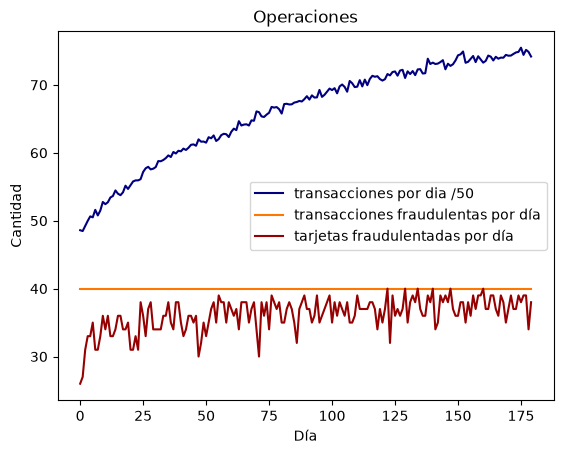

In [16]:
def get_transaction_stats(df):

    # Cantidad de transacciones por dia
    n_trans_dia = df.groupby(['step'])['amount'].size()
    # Cantidad de transacciones fraudulentas por día
    n_fraud_trans_dia = df.groupby(['step'])['fraud'].sum()
    # Cantidad de tarjetas comprometidas por día
    n_tarjetas_comprometidas_dia = df[df['fraud']==1].groupby(['step'])['customer'].nunique()

    data = pd.DataFrame({'tx_dia':n_trans_dia, 'fraud_dia':n_fraud_trans_dia, 'tarjetas':n_tarjetas_comprometidas_dia})

    return(data)

stats = get_transaction_stats(df)

fig, ax = plt.subplots()

cmap = plt.get_cmap('jet')
ax.plot(stats.index, stats['tx_dia']/50, color=cmap(0), label='transacciones por dia /50')
ax.plot(stats.index, stats['fraud_dia'], color=cmap(200), label='transacciones fraudulentas por día')
ax.plot(stats.index, stats['tarjetas'], color=cmap(250), label='tarjetas fraudulentadas por día')

ax.set_title('Operaciones')
ax.set_xlabel('Día')
ax.set_ylabel('Cantidad')
ax.legend()

## 5.2 Remoción de clientes comprometidos

Una ves que los clientes fueron fraudulentados, estos se van a ir sacando del dataset, ya que esto sería lo que haría el banco en la vida real.

__Customer actúa como nuestro identificador de la tarjeta/cuenta comprometida.__

In [17]:
def filtrar_clientes_comprometidos(df, train_df, validation_raw, test_raw,delay=7):
    
    # Clientes cuyo fraude ya es conocido gracias al train
    known_customers = set(train_df.loc[train_df['fraud'] == 1,'customer'])

    # Hasta este step ya conocemos los fraudes porque pertenecen al train
    last_known_step = train_df['step'].max()

    resultados = []

    for split in [validation_raw, test_raw]:

        filtered_days = []

        # Importante: procesar cronológicamente
        for day in sorted(split['step'].unique()):

            # Último día cuyos fraudes ya deberían conocerse
            known_until = day - delay - 1

            # Incorporar TODOS los nuevos fraudes conocidos desde la última actualización hasta known_until
            if known_until > last_known_step:
                new_known = df[(df['step'] > last_known_step) & (df['step'] <= known_until) & (df['fraud'] == 1)]['customer']
                known_customers.update(new_known)
                last_known_step = known_until

            # Operaciones del día actual
            day_df = split[split['step'] == day].copy()

            # Eliminar clientes que ya sabemos que están comprometidos
            day_df = day_df[~day_df['customer'].isin(known_customers)]

            filtered_days.append(day_df)

        filtered_split = pd.concat(filtered_days,ignore_index=True)
        resultados.append(filtered_split)

    validation_df, test_df = resultados

    return validation_df, test_df

In [18]:
validation_df, test_df = filtrar_clientes_comprometidos(
    df=df,
    train_df=train_df,
    validation_raw=validation,
    test_raw=test_raw,
    delay=7
)

### Visualización de la remoción

In [19]:
known_train = set(train_df.loc[train_df['fraud'] == 1,'customer'])

print('~~~~~~~~~~~ TRAIN ~~~~~~~~~~~')
print('Clientes únicos en train:',train_df['customer'].nunique())
print('Clientes comprometidos conocidos en train:', len(known_train), '| En procentaje:', len(known_train) / train_df['customer'].nunique() * 100)

print('\n~~~~~~~~~~~ VALIDATION ~~~~~~~~~~~')
print("Antes:", len(validation))
print("Después:", len(validation_df))
print("Eliminadas:", len(validation) - len(validation_df))

val_known = validation[validation['customer'].isin(known_train)]
print('\nTransacciones de validation pertenecientes a clientes ya comprometidos en train:', len(val_known))

print('Fraudes:', val_known['fraud'].sum())

frauds_per_customer = (df[df['fraud'] == 1].groupby('customer').size().sort_values(ascending=False))

print('\nClientes con más fraudes antes de la remoción:\n', frauds_per_customer.head(3))

print("\nFraudes validation antes:", validation["fraud"].sum())
print("Fraudes validation después:", validation_df["fraud"].sum())

print('\n~~~~~~~~~~~ TEST ~~~~~~~~~~~')
print("Antes:", len(test_raw))
print("Después:", len(test_df))
print("Eliminadas:",len(test_raw) - len(test_df))

print("\nFraudes Test antes:", test_raw["fraud"].sum())
print("Fraudes Test después:", test_df["fraud"].sum())

~~~~~~~~~~~ TRAIN ~~~~~~~~~~~
Clientes únicos en train: 4111
Clientes comprometidos conocidos en train: 1166 | En procentaje: 28.362928727803453

~~~~~~~~~~~ VALIDATION ~~~~~~~~~~~
Antes: 83437
Después: 60655
Eliminadas: 22782

Transacciones de validation pertenecientes a clientes ya comprometidos en train: 21679
Fraudes: 733

Clientes con más fraudes antes de la remoción:
 customer
C1350963410    144
C1849046345    127
C806399525     125
dtype: int64

Fraudes validation antes: 920
Fraudes validation después: 160

~~~~~~~~~~~ TEST ~~~~~~~~~~~
Antes: 85380
Después: 58305
Eliminadas: 27075

Fraudes Test antes: 920
Fraudes Test después: 113


<Axes: title={'center': 'Clientes comprometidos por primera vez por día'}, xlabel='step'>

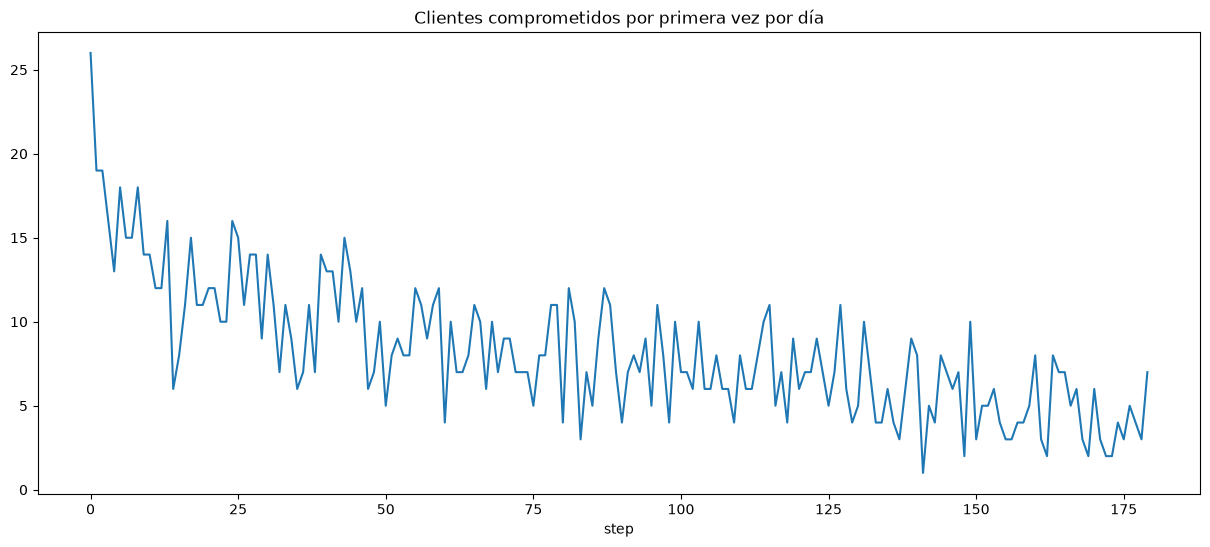

In [20]:
primer_fraude = (df[df["fraud"] == 1].groupby("customer")["step"].min())

primer_fraude_por_dia = (primer_fraude.value_counts().sort_index())

primer_fraude_por_dia.plot(figsize=(15, 6),title="Clientes comprometidos por primera vez por día")

### DECISIONES DE LA REMOCIÓN DE CLIENTES COMPROMETIDOS

Siguiendo el ejemplo del handbook las transacciones pertenecientes a clientes cuyo fraude ya debería ser conocido por la entidad fueron excluidas de los conjuntos de evaluación. Se utilizó un período de delay de siete días, de modo que un cliente sólo se considera conocido como comprometido una vez transcurrido dicho período desde una transacción fraudulenta.

En BankSim se identificaron 1.483 clientes con al menos una transacción fraudulenta. De ellos, 1.166 ya habían presentado fraude durante el período de entrenamiento comprendido entre los steps 0 y 119, equivalente aproximadamente al 78,6 %. Como consecuencia, el filtrado redujo los fraudes del conjunto de validación de 920 a 160. Este comportamiento se consideró coherente con el objetivo de evaluar la detección de clientes aún no conocidos como comprometidos, evitando contabilizar repetidamente fraudes pertenecientes a una cuenta que, bajo la hipótesis operativa adoptada, ya habría sido bloqueada.

Nota: Dado que BankSim identifica al customer pero no proporciona un identificador independiente de tarjeta, se asumió al cliente como unidad equivalente a la tarjeta/cuenta comprometida para adaptar la metodología del Handbook.

# 6. Preparación para machine learning

In [21]:
# Datos de entrenamiento
X_train = train_df.drop(columns=['fraud', 'customer', 'step']).copy()
y_train = train_df['fraud'].copy()

# Datos de validación
X_validation = validation_df.drop(columns=['fraud', 'customer', 'step']).copy()
y_validation = validation_df['fraud'].copy()

# Datos de prueba
X_test = test_df.drop(columns=['fraud', 'customer', 'step']).copy()
y_test = test_df['fraud'].copy()

In [22]:
# Definimos las variables categóricas
categorical_features = ['merchant', 'category']

# Definimos las variables numéricas
numerical_features = []

for column in X_train.columns:
    if column not in categorical_features:
        numerical_features.append(column)

### Preprocesamiento

In [23]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown="ignore",sparse_output=False), categorical_features)
    ], verbose_feature_names_out=False
)

In [24]:
X_train_processed = preprocessor.fit_transform(X_train)

X_validation_processed = preprocessor.transform(X_validation)

X_test_processed = preprocessor.transform(X_test)

In [25]:
# Para obtener los nombres de las columnas, sino es solo una matriz con información numérica.
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_validation_processed = pd.DataFrame(
    X_validation_processed,
    columns=feature_names,
    index=X_validation.index
)

In [26]:
print('Proporción de fraudes train:', y_train.sum()/y_train.count(),'\n', y_train.value_counts())
print('Proporción de fraudes validación:', y_validation.sum()/y_validation.count(),'\n', y_validation.value_counts())
print('Proporción de fraudes test:', y_test.sum()/y_test.count(),'\n', y_test.value_counts())

Proporción de fraudes train: 0.012802936140021445 
 fraud
0    370114
1      4800
Name: count, dtype: int64
Proporción de fraudes validación: 0.002637869920039568 
 fraud
0    60495
1      160
Name: count, dtype: int64
Proporción de fraudes test: 0.001938084212331704 
 fraud
0    58192
1      113
Name: count, dtype: int64


# 7. Modelos

Recordatorio -> vamos a utilizar la validación para comparar los modelos, seleccionar hiperparametros. El TEST solo lo vamos a usar con el modelo SELECCIONADO.

Esto es para que el test sea una evaluación independiente.

In [27]:
from sklearn.metrics import average_precision_score, roc_auc_score

In [28]:
def card_precision_top_k(predictions_df, top_k=100, remove_detected_compromised_cards=True):

    detected_customers = set() # Creamos este set que va a ir cargando los clientes que ya fueron comprometidos
    results = []

    for day in sorted(predictions_df["step"].unique()):

        # Transacciones del día
        df_day = predictions_df[predictions_df["step"] == day].copy()

        # Sacamos los clientes ya detectados en días anteriores
        df_day = df_day[~df_day["customer"].isin(detected_customers)]

        # Agrupar las transacciones por cliente
        df_day = (df_day.groupby("customer", as_index=False).agg(predictions=("predictions", "max"),fraud=("fraud", "max")))

        # Ordenar clientes por probabilidad de fraude
        df_day = df_day.sort_values("predictions", ascending=False)

        # Seleccionar los K clientes más sospechosos
        top_customers = df_day.head(top_k)

        # Clientes comprometidos correctamente detectados
        detected = top_customers.loc[top_customers["fraud"] == 1, "customer"]

        # Card Precision@K del día
        cp_k = len(detected) / top_k

        results.append({
            "step": day,
            "compromised_cards": int(df_day["fraud"].sum()),
            "detected_cards": len(detected),
            "card_precision": cp_k
        })

        # Simular el bloqueo de clientes detectados
        if remove_detected_compromised_cards:
            detected_customers.update(detected) # Aca actualizamos la lista luego de que pasa el dia n

    results_df = pd.DataFrame(results)

    mean_cp_k = results_df["card_precision"].mean()

    return mean_cp_k, results_df

Luego de sacar los clientes que ya fueron comprometidos, en validación quedaron 160 transacciones fraudulentas en un total de 23 días. Si tuvieramos un clasificador perfecto, el máximo teórico es inferior al 7%:
$$CP@100 ≤ \frac{160}{23 \times 100} = 0.069$$

Esto nos motiva a testear también con menor cantidad de investigadores, por ejemplo 10-20, de forma de saber que tan bien rinde el modelo si solo se pudieran investigar 30 casos.

## 7.1 Regresión logistica

In [29]:
from sklearn.linear_model import LogisticRegression

In [30]:
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [31]:
y_score = log_reg.predict_proba(X_validation_processed)
pd.DataFrame(y_score, columns=['NotFraud', 'Fraud']).head(5)

,NotFraud,Fraud
0,0.979220,0.020780
1,0.967457,0.032543
2,0.987372,0.012628
3,0.984138,0.015862
4,0.986408,0.013592


In [32]:
# Utilizamos ahora únicamente la columna Fraud
y_score = log_reg.predict_proba(X_validation_processed)[:,1]

# Verificar que los índices mantienen el mismo orden
assert X_validation_processed.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

### Precision@100

In [33]:
# Verificar que las etiquetas coinciden
assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score
cp_100, cp_per_day = card_precision_top_k(
    predictions_df,
    top_k=100
)

print(f"Card Precision@100: {cp_100:.4f}")
print(cp_per_day)

Card Precision@100: 0.0617
    step  compromised_cards  detected_cards  card_precision
0    127                 13              13            0.13
1    128                  6               6            0.06
2    129                  6               6            0.06
3    130                  5               5            0.05
4    131                 10              10            0.10
5    132                  8               8            0.08
6    133                  4               4            0.04
7    134                  4               4            0.04
8    135                  6               6            0.06
9    136                  4               4            0.04
10   137                  3               3            0.03
11   138                  6               6            0.06
12   139                  9               9            0.09
13   140                  8               8            0.08
14   141                  1               1            0.01
15   142     

### Precision@20

In [34]:
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2848
    step  compromised_cards  detected_cards  card_precision
0    127                 13              10            0.50
1    128                  6               5            0.25
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10               9            0.45
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               2            0.10
11   138                  6               6            0.30
12   139                  9               8            0.40
13   140                  8               6            0.30
14   141                  1               1            0.05
15   142      

### Average precision

In [35]:
ap = average_precision_score(y_validation, y_score)
print('Average Precision:', round(ap, 6))

Average Precision: 0.79849


### AUC-ROC Score

In [36]:
roc_auc = roc_auc_score(y_validation, y_score)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.997765


## 7.2 Random Forest

In [37]:
from sklearn.ensemble import RandomForestClassifier

In [38]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [39]:
y_score_rf = rf.predict_proba(X_validation_processed)
pd.DataFrame(y_score_rf, columns=['NotFraud', 'Fraud']).head(5)

,NotFraud,Fraud
0,0.42,0.58
1,1.00,0.00
2,1.00,0.00
3,1.00,0.00
4,1.00,0.00


### Precision@20

In [40]:
y_score_rf = rf.predict_proba(X_validation_processed)[:,1]

assert X_validation_processed.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_rf
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2957
    step  compromised_cards  detected_cards  card_precision
0    127                 13              11            0.55
1    128                  6               6            0.30
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10              10            0.50
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               2            0.10
11   138                  6               6            0.30
12   139                  9               8            0.40
13   140                  8               6            0.30
14   141                  1               1            0.05
15   142      

### Average precision

In [41]:
ap = average_precision_score(y_validation, y_score_rf)
print('Average Precision:', round(ap, 6))

Average Precision: 0.86113


### AUC-ROC Score

In [42]:
roc_auc = roc_auc_score(y_validation, y_score_rf)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.995869


## 7.3 XGBoost

In [43]:
import xgboost as xgb
from xgboost import XGBClassifier

In [44]:
xgb = XGBClassifier(device='cuda',random_state=42)
xgb.fit(X_train_processed, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [45]:
y_score_xgb = xgb.predict_proba(X_validation_processed)
pd.DataFrame(y_score_xgb, columns=['NotFraud', 'Fraud']).head(5)

/home/ginoanci/Documentos/Diplomaturas/Trabajos_Practicos/Practicos_Diplo_CD/TF/.venv/lib64/python3.13/site-packages/xgboost/core.py:569: UserWarning: [18:10:58] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


,NotFraud,Fraud
0,0.142865,0.857135
1,0.997759,0.002241
2,0.998439,0.001561
3,0.998656,0.001344
4,0.998394,0.001606


### Precision@20

In [46]:
y_score_xgb = xgb.predict_proba(X_validation_processed)[:,1]

assert X_validation_processed.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_xgb
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2870
    step  compromised_cards  detected_cards  card_precision
0    127                 13              11            0.55
1    128                  6               6            0.30
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10               9            0.45
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               3            0.15
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               3            0.15
11   138                  6               6            0.30
12   139                  9               8            0.40
13   140                  8               7            0.35
14   141                  1               1            0.05
15   142      

### Average precision

In [47]:
ap = average_precision_score(y_validation, y_score_xgb)
print('Average Precision:', round(ap, 6))

Average Precision: 0.707471


### AUC-ROC Score

In [48]:
roc_auc = roc_auc_score(y_validation, y_score_xgb)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.979651


## 7.4 Red Neuronal Feed-Forward

"For our fraud detection neural network, the ReLU activation will be used for the hidden layer and a Sigmoid activation for the output layer." Ademas el autor del handbook de fraude utiliza 2 capas densas ocultas de 500 neuronas.

In [49]:
def feed_forward(entry):
    model = keras.Sequential([
        keras.Input(shape=(entry.shape[1],)),

        layers.Dense(500, activation='relu'),
        layers.Dropout(0.2),

        layers.Dense(500, activation='relu'),
        layers.Dropout(0.2),

        layers.Dense(1, activation='sigmoid')
    ])

    # Compilación del modelo
    model.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

    return model


In [50]:
early_stopping = EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint(monitor='val_pr_auc',mode="max", save_best_only=True, filepath="model_checkpoint.keras")
callback_list    = [early_stopping,model_checkpoint]

In [51]:
keras.utils.set_random_seed(42)
keras.backend.clear_session()
model = feed_forward(X_train_processed)
model.summary()

I0000 00:00:1791839459.092996   16894 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1951 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650, pci bus id: 0000:01:00.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 500)            │        42,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           501 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 293,501 (1.12 MB)

 Trainable params: 293,501 (1.12 MB)

 Non-trainable params: 0 (0.00 B)

In [52]:
model.fit(X_train_processed,y_train, validation_data=(X_validation_processed, y_validation), epochs=100, batch_size=128, callbacks=callback_list)

Epoch 1/100


2026-10-12 18:11:00.706944: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f96b0005ae0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-12 18:11:00.706959: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce GTX 1650, Compute Capability 7.5
2026-10-12 18:11:00.734440: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-12 18:11:01.389582: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92600


 112/2930 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - loss: 0.0364 - pr_auc: 0.6749

I0000 00:00:1791839462.945076   64587 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2930/2930 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - loss: 0.0124 - pr_auc: 0.8936 - val_loss: 0.0037 - val_pr_auc: 0.8494
Epoch 2/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0099 - pr_auc: 0.9277 - val_loss: 0.0041 - val_pr_auc: 0.8517
Epoch 3/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0093 - pr_auc: 0.9344 - val_loss: 0.0039 - val_pr_auc: 0.8580
Epoch 4/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0089 - pr_auc: 0.9390 - val_loss: 0.0036 - val_pr_auc: 0.8713
Epoch 5/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0087 - pr_auc: 0.9417 - val_loss: 0.0033 - val_pr_auc: 0.8777
Epoch 6/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0085 - pr_auc: 0.9435 - val_loss: 0.0039 - val_pr_auc: 0.8606
Epoch 7/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0084 - pr_auc: 0.9448 - val_loss: 0.0036 - val_pr_auc: 0.8764
Epoch 8/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0083 - pr_auc: 0.9457 - val_loss: 0.0034 - val_pr_auc: 0.

In [53]:
loss_df = pd.DataFrame(model.history.history)
loss_df.tail(20)

,loss,pr_auc,val_loss,val_pr_auc
0,0.012358,0.893605,0.003685,0.849363
1,0.009869,0.927735,0.004135,0.851672
2,0.009263,0.934394,0.003888,0.858046
3,0.008876,0.938988,0.003606,0.871275
4,0.008732,0.941686,0.003288,0.877683
5,0.008487,0.943523,0.003885,0.860602
6,0.008414,0.944788,0.003594,0.876354
7,0.008327,0.945712,0.003402,0.871277
8,0.008261,0.946530,0.003768,0.871121
9,0.008200,0.946481,0.003856,0.859658


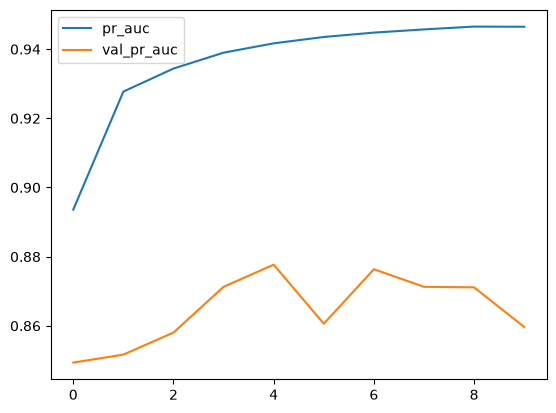

In [54]:
loss_df[['pr_auc', 'val_pr_auc']].plot(legend=True)
plt.show()

### Precision@20

In [55]:
y_score_nn = model.predict(X_validation_processed, verbose=0).ravel()

In [56]:
assert X_validation_processed.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_nn
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.3000
    step  compromised_cards  detected_cards  card_precision
0    127                 13              12            0.60
1    128                  6               6            0.30
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10              10            0.50
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               2            0.10
11   138                  6               6            0.30
12   139                  9               9            0.45
13   140                  8               7            0.35
14   141                  1               1            0.05
15   142      

### Average precision

In [57]:
ap = average_precision_score(y_validation, y_score_nn)
print('Average Precision:', round(ap, 6))

Average Precision: 0.883225


### AUC-ROC Score

In [58]:
roc_auc = roc_auc_score(y_validation, y_score_nn)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.999257


## 8. Modelos sin feature engieniering

Como los resultados de las metricas son muy optimistas, determinamos que sería conveniente comparar las metricas que obtuvimos con el feature a modelos entrenados sin el feature

Para probar los modelos sin el feature se van a eliminar las columnas que se crearon de las divisiones ya procesadas, estas incluyen:
- 'tx_count_last_1d'
- 'avg_amount_last_1d'
- 'tx_count_last_7d'
- 'avg_amount_last_7d'
- 'tx_count_last_30d'
- 'avg_amount_last_30d'
- 'merchant_tx_delayed_1d'
- 'merchant_risk_1d'
- 'merchant_tx_delayed_7d'
- 'merchant_risk_7d'
- 'merchant_tx_delayed_30d'
- 'merchant_risk_30d'
- 'category_tx_delayed_1d'
- 'category_risk_1d'
- 'category_tx_delayed_7d'
- 'category_risk_7d'
- 'category_tx_delayed_30d'
- 'category_risk_30d'

In [59]:
X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=X_train_processed.columns,
    index=X_test.index
)

In [60]:
# Columnas creadas durante el feature engineering
feature_columns = [
    'tx_count_last_1d', 'avg_amount_last_1d',
    'tx_count_last_7d', 'avg_amount_last_7d',
    'tx_count_last_30d', 'avg_amount_last_30d',

    'merchant_tx_delayed_1d', 'merchant_risk_1d',
    'merchant_tx_delayed_7d', 'merchant_risk_7d',
    'merchant_tx_delayed_30d', 'merchant_risk_30d',

    'category_tx_delayed_1d', 'category_risk_1d',
    'category_tx_delayed_7d', 'category_risk_7d',
    'category_tx_delayed_30d', 'category_risk_30d'
]

X_train_no_feature = X_train_processed.drop(
    columns=feature_columns
).copy()

X_validation_no_feature = X_validation_processed.drop(
    columns=feature_columns
).copy()

X_test_no_feature = X_test_processed.drop(
    columns=feature_columns
).copy()

### 8.1 Regresión logística

In [61]:
log_reg_no_feature = LogisticRegression(random_state=42)
log_reg_no_feature.fit(X_train_no_feature, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [62]:
y_score_no_feature = log_reg_no_feature.predict_proba(X_validation_no_feature)
pd.DataFrame(y_score_no_feature, columns=['NotFraud', 'Fraud']).head(5)

,NotFraud,Fraud
0,0.926750,0.073250
1,0.966022,0.033978
2,0.987631,0.012369
3,0.979458,0.020542
4,0.986929,0.013071


In [63]:
# Utilizamos ahora únicamente la columna Fraud
y_score_no_feature = log_reg_no_feature.predict_proba(X_validation_no_feature)[:,1]

# Verificar que los índices mantienen el mismo orden
assert X_validation_no_feature.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

### Precision@20

In [64]:
predictions_df["predictions"] = y_score_no_feature
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2826
    step  compromised_cards  detected_cards  card_precision
0    127                 13              11            0.55
1    128                  6               5            0.25
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10               9            0.45
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               2            0.10
11   138                  6               5            0.25
12   139                  9               8            0.40
13   140                  8               7            0.35
14   141                  1               1            0.05
15   142      

### Average precision

In [65]:
ap = average_precision_score(y_validation, y_score_no_feature)
print('Average Precision:', round(ap, 6))

Average Precision: 0.755506


el feature engineering parece mejorar Average Precision en aproximadamente 0.0435 puntos.

### AUC-ROC Score

In [66]:
roc_auc = roc_auc_score(y_validation, y_score_no_feature)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.997548


La poca diferencia entre metricas sugiere que las características originales de BankSim, especialmente las categorías comerciales y los importes, pueden explicar cuando o no va a haber fraude.

### 8.2 Random Forest No feature

In [67]:
rf_no_feature = RandomForestClassifier(random_state=42)
rf_no_feature.fit(X_train_no_feature, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [68]:
y_score_rf_no_feature = rf_no_feature.predict_proba(X_validation_no_feature)
pd.DataFrame(y_score_rf_no_feature, columns=['NotFraud', 'Fraud']).head(5)

,NotFraud,Fraud
0,0.02,0.98
1,1.00,0.00
2,1.00,0.00
3,1.00,0.00
4,1.00,0.00


### Precision@20

In [69]:
y_score_rf_no_feature = rf_no_feature.predict_proba(X_validation_no_feature)[:,1]

assert X_validation_no_feature.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_rf_no_feature
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2696
    step  compromised_cards  detected_cards  card_precision
0    127                 13              10            0.50
1    128                  6               5            0.25
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10               8            0.40
5    132                  8               6            0.30
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               3            0.15
11   138                  6               4            0.20
12   139                  9               8            0.40
13   140                  8               5            0.25
14   141                  1               1            0.05
15   142      

### Average precision

In [70]:
ap = average_precision_score(y_validation, y_score_rf_no_feature)
print('Average Precision:', round(ap, 6))

Average Precision: 0.709099


### AUC-ROC Score

In [71]:
roc_auc = roc_auc_score(y_validation, y_score_rf_no_feature)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.930304


### 8.3 XGBoost No feature

In [72]:
xgb_no_feature = XGBClassifier(device='cuda',random_state=42)
xgb_no_feature.fit(X_train_no_feature, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [73]:
y_score_xgb_no_feature = xgb_no_feature .predict_proba(X_validation_no_feature)
pd.DataFrame(y_score_xgb_no_feature, columns=['NotFraud', 'Fraud']).head(5)

,NotFraud,Fraud
0,0.523111,0.476889
1,0.980861,0.019139
2,0.996170,0.003830
3,0.991683,0.008317
4,0.996170,0.003830


### Precision@20

In [74]:
y_score_xgb_no_feature = xgb_no_feature.predict_proba(X_validation_no_feature)[:,1]

assert X_validation_no_feature.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_xgb_no_feature
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2913
    step  compromised_cards  detected_cards  card_precision
0    127                 13              11            0.55
1    128                  6               5            0.25
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10              10            0.50
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               3            0.15
11   138                  6               5            0.25
12   139                  9               8            0.40
13   140                  8               7            0.35
14   141                  1               1            0.05
15   142      

### Average precision

In [75]:
ap = average_precision_score(y_validation, y_score_xgb_no_feature)
print('Average Precision:', round(ap, 6))

Average Precision: 0.789103


### AUC-ROC Score

In [76]:
roc_auc = roc_auc_score(y_validation, y_score_xgb_no_feature)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.99843


### Red Neuronal Feed-Forward No feature

In [77]:
early_stopping_no_feature   = EarlyStopping(monitor="val_pr_auc", mode="max", patience=5, restore_best_weights=True)
model_checkpoint_no_feature = ModelCheckpoint(monitor='val_pr_auc',mode="max", save_best_only=True, filepath="model_checkpoint_no_feature.keras")
callback_list_no_feature    = [early_stopping_no_feature,model_checkpoint_no_feature]

In [78]:
keras.utils.set_random_seed(42)
keras.backend.clear_session()
model_no_feature = feed_forward(X_train_no_feature)
model_no_feature.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 500)            │        33,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 500)            │       250,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           501 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 284,501 (1.09 MB)

 Trainable params: 284,501 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [79]:
model_no_feature.fit(X_train_no_feature,y_train, validation_data=(X_validation_no_feature, y_validation), epochs=100, batch_size=128, callbacks=callback_list_no_feature)

Epoch 1/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.0148 - pr_auc: 0.8592 - val_loss: 0.0040 - val_pr_auc: 0.8196
Epoch 2/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0127 - pr_auc: 0.8901 - val_loss: 0.0039 - val_pr_auc: 0.8242
Epoch 3/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0125 - pr_auc: 0.8928 - val_loss: 0.0038 - val_pr_auc: 0.8263
Epoch 4/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0125 - pr_auc: 0.8934 - val_loss: 0.0039 - val_pr_auc: 0.8289
Epoch 5/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0124 - pr_auc: 0.8937 - val_loss: 0.0038 - val_pr_auc: 0.8281
Epoch 6/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0124 - pr_auc: 0.8941 - val_loss: 0.0038 - val_pr_auc: 0.8277
Epoch 7/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0124 - pr_auc: 0.8943 - val_loss: 0.0038 - val_pr_auc: 0.8305
Epoch 8/100
2930/2930 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - loss: 0.0124 - pr_auc: 0.8943 - val_loss: 0.0038 - va

In [80]:
loss_df = pd.DataFrame(model_no_feature.history.history)
loss_df.tail(20)

,loss,pr_auc,val_loss,val_pr_auc
0,0.014831,0.859168,0.004002,0.819565
1,0.012665,0.890078,0.003892,0.824231
2,0.012484,0.892832,0.003825,0.826283
3,0.012451,0.893370,0.003855,0.828935
4,0.012411,0.893696,0.003804,0.828082
5,0.012408,0.894090,0.003779,0.827683
6,0.012368,0.894333,0.003848,0.830529
7,0.012364,0.894282,0.003834,0.828127
8,0.012345,0.894904,0.003738,0.830209
9,0.012339,0.894849,0.003757,0.828833


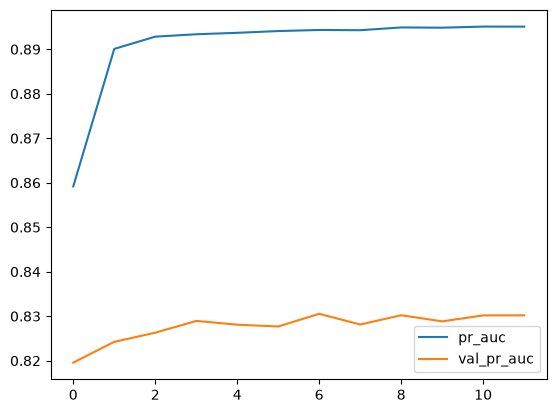

In [81]:
loss_df[['pr_auc', 'val_pr_auc']].plot(legend=True)
plt.show()

### Precision@20

In [82]:
y_score_nn_no_feature = model_no_feature.predict(X_validation_no_feature, verbose=0).ravel()

In [83]:
assert X_validation_no_feature.index.equals(y_validation.index) 
predictions_df = validation_df.loc[y_validation.index,["step", "customer", "fraud"]].copy()

assert np.array_equal(
    predictions_df["fraud"].to_numpy(),
    y_validation.to_numpy()
)

predictions_df["predictions"] = y_score_nn_no_feature
cp_20, cp20_per_day = card_precision_top_k(
    predictions_df,
    top_k=20
)

print(f"Card Precision@20: {cp_20:.4f}")
print(cp20_per_day)

Card Precision@20: 0.2891
    step  compromised_cards  detected_cards  card_precision
0    127                 13              11            0.55
1    128                  6               5            0.25
2    129                  6               6            0.30
3    130                  5               5            0.25
4    131                 10               9            0.45
5    132                  8               8            0.40
6    133                  4               4            0.20
7    134                  4               4            0.20
8    135                  6               6            0.30
9    136                  4               4            0.20
10   137                  3               3            0.15
11   138                  6               5            0.25
12   139                  9               8            0.40
13   140                  8               6            0.30
14   141                  1               1            0.05
15   142      

### Average Precision

In [84]:
ap = average_precision_score(y_validation, y_score_nn_no_feature)
print('Average Precision:', round(ap, 6))

Average Precision: 0.830955


### AUC-ROC Score

In [85]:
roc_auc = roc_auc_score(y_validation, y_score_nn_no_feature)
print('AUC-ROC score:', round(roc_auc, 6))

AUC-ROC score: 0.998382


## Conclusiones

El feature engineering tiene valor predictivo, pero su beneficio depende del modelo. De los modelos probados XGBoost tuvo un rendimiento inferior con el feature engineering.

Las métricas tan optimistas tanto con y sin feature nos hace confirmar nuestra teoría de que el dataset de BankSim tiene patrones de fraude que son facilmente identificable para los modelos.

El numero de clientes comprometidos por día es reducido, lo que investigar solo 20 tarjetas permite alcanzar un precision@20 muy próximo a su límite.

## Evaluación con test

El mejor modelo según las métricas fue la red neuronal Feed-Forward con feature engieniering, por lo tanto es la que se llevaria a la aplicación real.

In [86]:
# Predicciones sobre Test
y_score_test = model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Métricas
ap_test = average_precision_score(
    y_test, y_score_test
)

roc_test = roc_auc_score(
    y_test, y_score_test
)

# Preparar Card Precision@20
assert X_test_processed.index.equals(y_test.index)

predictions_test = test_df.loc[
    y_test.index,
    ["step", "customer", "fraud"]
].copy()

assert np.array_equal(
    predictions_test["fraud"].to_numpy(),
    y_test.to_numpy()
)

predictions_test["predictions"] = y_score_test

cp20_test, cp20_per_day_test = card_precision_top_k(
    predictions_test,
    top_k=20
)

print(f"Average Precision: {ap_test:.6f}")
print(f"ROC-AUC: {roc_test:.6f}")
print(f"CP@20: {cp20_test:.6f}")

Average Precision: 0.880031
ROC-AUC: 0.999320
CP@20: 0.223913


## Gráficos

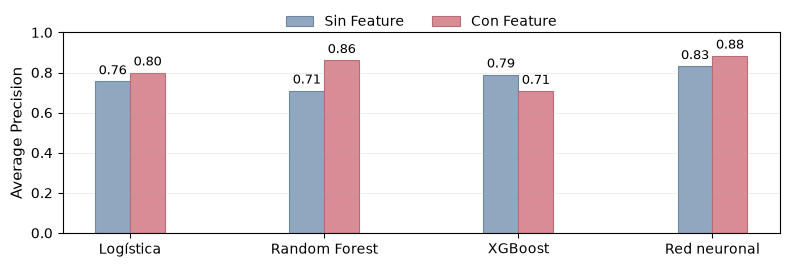

In [87]:
modelos = [
    "Logística",
    "Random Forest",
    "XGBoost",
    "Red neuronal"
]

ap_con = [0.799, 0.861130, 0.707471, 0.883225]
ap_sin = [0.755506, 0.709099, 0.789103, 0.830955]

x = np.arange(len(modelos))
ancho = 0.18

fig, ax = plt.subplots(figsize=(8, 2.8))

barras_sin = ax.bar(
    x - ancho/2,
    ap_sin,
    ancho,
    label="Sin Feature",
    color='#8FA8BF',
    edgecolor="#6F879C",
    linewidth=0.8
)

barras_con = ax.bar(
    x + ancho/2,
    ap_con,
    ancho,
    label="Con Feature",
    color='#D98C95',
    edgecolor="#B56E78",
    linewidth=0.8
)

ax.bar_label(barras_sin, fmt="%.2f", padding=3, fontsize=9)
ax.bar_label(barras_con, fmt="%.2f", padding=3, fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=10)
ax.set_ylim(0, 1)
ax.set_ylabel("Average Precision", fontsize=11)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=2,
    frameon=False,
    fontsize=10
)

ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.savefig("rendimiento_modelos.pgf", bbox_inches="tight")

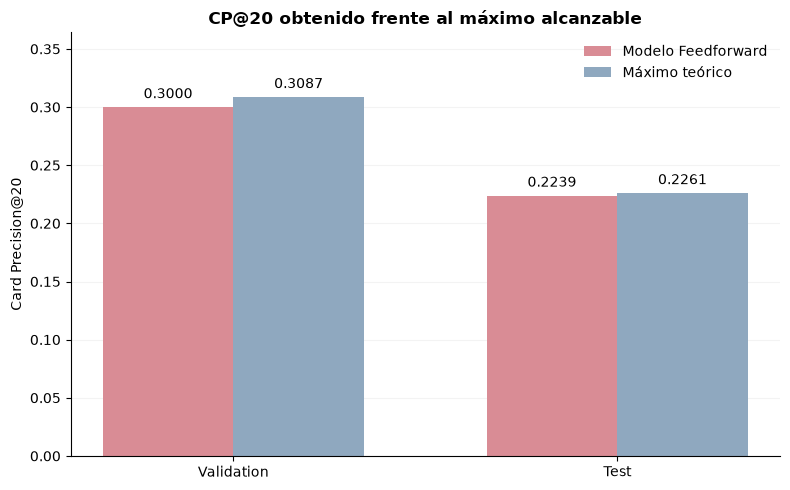

Clientes comprometidos en Validation: 142
Clientes comprometidos en Test: 104


In [89]:
# Cantidad de días evaluados
dias_validation = validation_df["step"].nunique()
dias_test = test_df["step"].nunique()

# Clientes comprometidos distintos en cada período
fraudes_validation = validation_df.loc[
    validation_df["fraud"] == 1, "customer"
].nunique()

fraudes_test = test_df.loc[
    test_df["fraud"] == 1, "customer"
].nunique()

k = 20

max_validation = fraudes_validation / (k * dias_validation)
max_test = fraudes_test / (k * dias_test)

cp_obtenido = [0.300000, 0.223913]
cp_maximo = [max_validation, max_test]

x = np.arange(2)
ancho = 0.34

fig, ax = plt.subplots(figsize=(8, 5))

barras_real = ax.bar(
    x - ancho/2,
    cp_obtenido,
    ancho,
    label="Modelo Feedforward",
    color='#D98C95'
)

barras_max = ax.bar(
    x + ancho/2,
    cp_maximo,
    ancho,
    label="Máximo teórico",
    color='#8FA8BF'
)

ax.bar_label(barras_real, fmt="%.4f", padding=4)
ax.bar_label(barras_max, fmt="%.4f", padding=4)

ax.set_xticks(x)
ax.set_xticklabels(["Validation", "Test"])
ax.set_ylabel("Card Precision@20")
ax.set_title(
    "CP@20 obtenido frente al máximo alcanzable",
    fontweight="bold"
)

ax.set_ylim(0, max(cp_maximo) * 1.18)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
#plt.savefig("cp20_maximo.pdf", bbox_inches="tight")
plt.show()

print("Clientes comprometidos en Validation:", fraudes_validation)
print("Clientes comprometidos en Test:", fraudes_test)
